# Prática 2 · Treinar e testar, sozinhos

**VERSÃO DO FACILITADOR: o código escrito, com notas.** Não copiar para os computadores dos alunos.

**18 minutos (12:17–12:35) · em pares, sozinhos** · depois da Aula 2

**A missão:** fazer vocês a separação em treino e teste, treinar a floresta, calcular as duas notas e fazer o exame com o mapa oficial. Desta vez, o teste são os **primeiros** 5 + 5 pontos (na aula eram os últimos).

**Os dados:** os mesmos da Aula 2: a imagem da cheia, os pontos e o mapa oficial.  
**Treino e teste:** desta vez, **teste** = os primeiros 5 + 5 pontos (250 píxeis) e **treino** = os outros 10 + 10 (488 píxeis); **exame** = o mapa oficial.  
**O algoritmo:** floresta aleatória com 100 árvores, e depois com uma só.

**Como praticar:** agora são vocês que escrevem o código. Em cada passo há uma célula com uma **pista**
(linhas que começam por `#`). Escrevam o código por baixo da pista (podem copiar a pista, tirar o `#` e trocar os
`...`), corram a célula com **Shift + Enter**, e depois corram a célula de verificação: diz «Certo!», ou
«Ainda não» com uma pista. A aula guiada que acabaram de ver tem os mesmos passos: usem-na como modelo.

> **Nota para o facilitador.** Resultados esperados com esta separação: 488 exemplos de treino e 250 de teste; treino 100,0 %, teste 99,6 %; no mapa oficial 97,0 %, com 211 falsos alarmes e 10 056 píxeis de água perdida; com 1 árvore, 96,4 % no teste.

## Passo 1 · Abrir as ferramentas e a imagem da cheia

In [1]:
import os, sys
for pasta in [".", os.path.join("..", "..", "2_pratica")]:          # a pasta onde está o ferramentas.py
    if os.path.exists(os.path.join(pasta, "ferramentas.py")):
        sys.path.insert(0, pasta)
        break
from ferramentas import *
from sklearn.ensemble import RandomForestClassifier
cheia = carregar("incomati_2026_cheia.npz")
pontos = pontos_da_equipa(2026)
print("Ferramentas prontas.")

Ferramentas prontas.


## Passo 2 · Separar: treino e teste

Cada lista tem 15 pontos. Os **primeiros 5** (`[:5]`) ficam para o teste; os **outros 10** (`[5:]`) para o treino. Façam o mesmo para a terra (`pontos["nao_agua"]`).

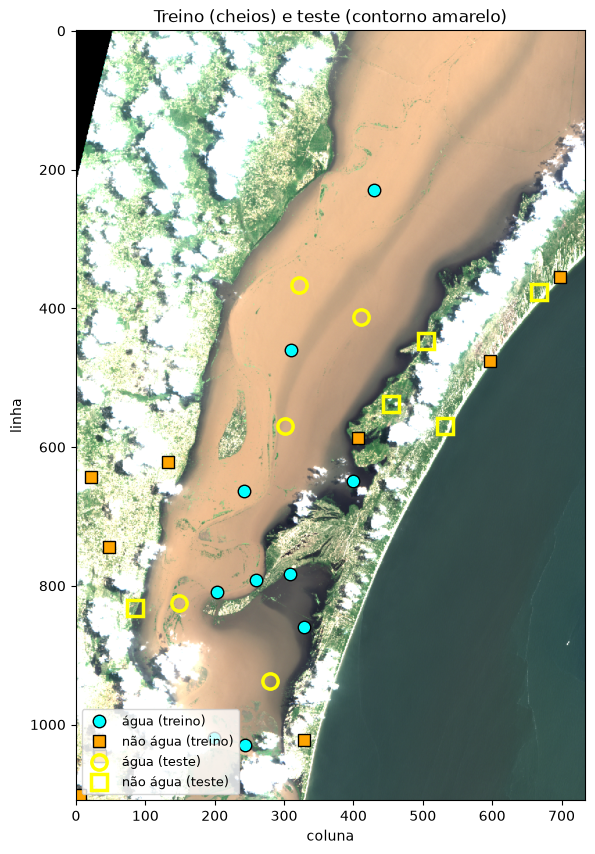

In [2]:
agua_teste = pontos["agua"][:5]
agua_treino = pontos["agua"][5:]
terra_teste = pontos["nao_agua"][:5]
terra_treino = pontos["nao_agua"][5:]
ver_imagem(cheia, "Treino (cheios) e teste (contorno amarelo)", agua_treino, terra_treino, agua_teste, terra_teste)

In [3]:
verificar_passo("2.2")      # a verificação: corram sem mudar nada

Certo! Treino: 10 + 10 pontos. Teste: os primeiros 5 + 5, que o modelo nunca vai ver no treino.


## Passo 3 · As tabelas do treino e do teste

Uma tabela para cada lado (Aula 2, Passo 2).

In [4]:
treino = tabela_de_exemplos(cheia, agua_treino, terra_treino)
teste = tabela_de_exemplos(cheia, agua_teste, terra_teste)

In [5]:
verificar_passo("2.3")      # a verificação: corram sem mudar nada

Certo! 488 exemplos de treino e 250 de teste.


## Passo 4 · Treinar a floresta

Uma floresta de 100 árvores, treinada **só com o treino** (Aula 2, Passo 3).

In [6]:
floresta = RandomForestClassifier(n_estimators=100, random_state=0)
floresta.fit(treino[BANDAS], treino["rótulo"])

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [7]:
verificar_passo("2.4")      # a verificação: corram sem mudar nada

Certo! A floresta de 100 árvores foi treinada só com o treino.


## Passo 5 · As duas notas

Calculem o acerto no treino e no teste (Aula 2, Passo 4).

In [8]:
nota_treino = acerto(treino["rótulo"], floresta.predict(treino[BANDAS]))
nota_teste = acerto(teste["rótulo"], floresta.predict(teste[BANDAS]))
print("Treino:", percentagem(nota_treino), "   Teste:", percentagem(nota_teste))

Treino: 100,0 %    Teste: 99,6 %


In [9]:
verificar_passo("2.5")      # a verificação: corram sem mudar nada

Certo! Acerto no treino 100,0 %; no teste 99,6 %.


## Passo 6 · O exame com o mapa oficial e a matriz de confusão

Aula 2, Passos 5 e 6.

Acerto no exame: 97,0 %


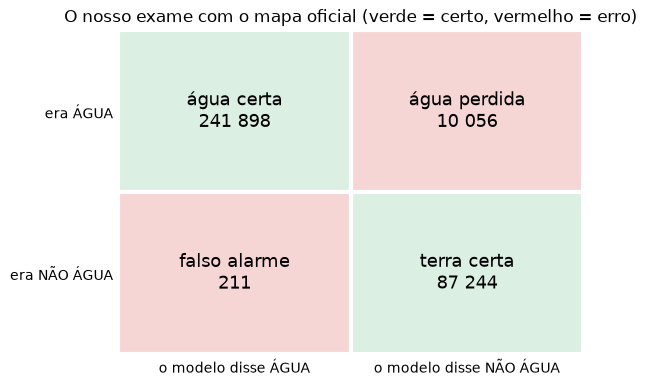

água certa       241 898 píxeis
água perdida      10 056 píxeis
falso alarme         211 píxeis
terra certa       87 244 píxeis


In [10]:
verdade, previsto = exame_mapa_oficial(floresta, cheia)
print("Acerto no exame:", percentagem(acerto(verdade, previsto)))
erros = matriz_de_confusao(verdade, previsto, "O nosso exame com o mapa oficial")

In [11]:
verificar_passo("2.6")      # a verificação: corram sem mudar nada

Certo! 211 falsos alarmes e 10 056 píxeis de água perdida.


## Passo 7 · E com uma só árvore?

Treinem uma floresta com `n_estimators=1` e calculem o acerto no teste em `nota_teste_1`.

In [12]:
uma = RandomForestClassifier(n_estimators=1, random_state=0)
uma.fit(treino[BANDAS], treino["rótulo"])
nota_teste_1 = acerto(teste["rótulo"], uma.predict(teste[BANDAS]))
print("Com uma só árvore, no teste:", percentagem(nota_teste_1))

Com uma só árvore, no teste: 96,4 %


In [13]:
verificar_passo("2.7")      # a verificação: corram sem mudar nada

Certo! Com uma só árvore, o acerto no teste é 96,4 %.


## Para pensar

Porque é que não se avalia um modelo com os exemplos do treino?

a) porque demora mais tempo  
b) porque o modelo já os viu: a nota sai boa de mais  
c) porque o computador não deixa

In [14]:
resposta = "b"
verificar("P2.a", resposta)

Certo! O modelo já conhece os exemplos do treino: a nota sairia boa de mais e não provaria nada.


Com uma só árvore, o acerto no teste...

a) sobe  
b) desce  
c) fica igual

In [15]:
resposta = "b"
verificar("P2.b", resposta)

Certo! Com uma só árvore, o acerto no teste desce. Muitas árvores a votar corrigem os erros umas das outras.


Num aviso de cheias, qual dos erros é mais perigoso?

a) o falso alarme (era terra e disse água)  
b) a água perdida (era água e disse terra)

In [16]:
resposta = "b"
verificar("P2.c", resposta)

Certo! Água perdida quer dizer que havia água e o modelo não a viu: uma pessoa pode ficar sem aviso.


**Para a apresentação:** anotem o acerto no teste e o número de falsos alarmes.

## O que aprendemos

- Fizeram sozinhos a **separação** em treino e teste, o treino, as duas notas e o exame.
- Com outra separação, os números mudam um pouco, mas a lição é a mesma: a nota que conta é a do teste.

## Guardar os modelos e as separações (só na versão do facilitador)

Ficam nas pastas `modelos_treinados/` e `separacoes/`, ao lado deste notebook. Para usar um modelo noutro notebook: `modelo = joblib.load("modelos_treinados/...joblib")`.

In [17]:
import joblib
os.makedirs("modelos_treinados", exist_ok=True)
os.makedirs("separacoes", exist_ok=True)
joblib.dump(floresta, "modelos_treinados/pratica2_floresta_100_arvores.joblib")
pd.DataFrame([(l, c, 1) for l, c in agua_treino] + [(l, c, 0) for l, c in terra_treino],
             columns=["linha", "coluna", "rótulo"]).to_csv("separacoes/pratica2_pontos_treino.csv", index=False)
pd.DataFrame([(l, c, 1) for l, c in agua_teste] + [(l, c, 0) for l, c in terra_teste],
             columns=["linha", "coluna", "rótulo"]).to_csv("separacoes/pratica2_pontos_teste.csv", index=False)
print("Guardado em modelos_treinados/ e separacoes/.")

Guardado em modelos_treinados/ e separacoes/.


## Se aparecer um erro

Leiam a **última linha** da mensagem vermelha.

| A última linha diz | O que fazer |
| --- | --- |
| `NameError: name '...' is not defined` | Saltaram uma célula. Corram as células por ordem, a partir do Passo 1. |
| `FileNotFoundError: Não encontrei ...` | Abram o notebook a partir da pasta `Workshop_2/2_pratica`. |
| `ModuleNotFoundError` | Falta uma biblioteca neste computador: chamem um facilitador. |
| `NotFittedError` ou «O modelo ainda não foi treinado» | Falta treinar o modelo: corram a célula com `.fit(...)`. |
| `SyntaxError` | Falta uma aspa, um parêntese ou uma vírgula. Comparem com o exemplo. |
| «Falta preencher» | Troquem os `...` pela vossa resposta. |

Se nada resultar: menu **Kernel**, depois **Restart Kernel and Run All Cells**.